# Project week 7

For the project this week, you are given a video of a ball rolling over a surface. Your job is now to detect the ball, track the position, velocity and acceleration using a Kalman filter, and finally draw the currently tracked position and predicted position of the ball in the images, while also printing the whole predicted state in either the image or the terminal.

The video "rolling_ball_result.mp4" shows what the end result could look like.

You have to make the Kalman filter yourselves, i.e. initialize the matrices and make a update and predict function. You are of course allowed to use numpy.

You can use the code below and fill in the missing parts.



# Comment section of the exercise
#### Ball tracking with a Kalman filter

- Detection. Each frame is converted to HSV and thresholded on the ball’s colour, which gives a binary mask. We clean the mask with an opening and a closing, keep the largest contour, and use minEnclosingCircle to get the ball’s centre. That centre is the measurement for the filter. If no blob is large enough, we treat the ball as not visible.

- Kalman filter. The state has six variables: position, velocity and acceleration in x and y. F comes from the constant-acceleration equations with dt = 1 (p' = p + v + ½a, v' = v + a, a' = a), with one block per axis because x and y are independent. H selects only the positions, since that is all the camera measures. P starts large because we know nothing about the initial state, and R sets how much we trust the detector.

- Tracking and occlusion. In every frame we run the update only if the ball was detected, and the prediction always. When the ball is hidden, the filter keeps moving the estimate using the last velocity and acceleration it inferred, while P grows. This lets it follow the ball behind the obstacle, and when the ball reappears it corrects itself within a few frames.

Finally to save the tracking output as a video file, VideoWriter is used, using the source video's dimensions, framerate, and the mp4v codec. Inside the main processing loop, each annotated frame with containing the detected and predicted circles and kinematic state text is written sequentially to result.mp4 using out.write(frame). Finally, after all frames are processed, out.release() is called to properly close the file stream and finalize the output video.

In [18]:
import cv2
import numpy as np


def update(x, P, Z, H, R):
    y = Z - np.dot(H, x)                          # Innovation
    S = np.dot(H, np.dot(P, H.T)) + R             # Innovation covariance
    K = np.dot(P, np.dot(H.T, np.linalg.pinv(S))) # Kalman gain
    x = x + np.dot(K, y)                          # State update
    P = np.dot((np.eye(6) - np.dot(K, H)), P)             # Covariance update
    return [x, P]
    
def predict(x, P, F, u):
    x = np.dot(F, x) + u          # Predict next state
    P = np.dot(F, np.dot(P, F.T)) # Predict next covariance
    return [x, P]
    
    
### Initialize Kalman filter ###
# The initial state (6x1).
kalman_x = np.zeros((6, 1))

# The initial uncertainty (6x6).
P = np.eye(6) * 1000

# The external motion (6x1).
u = np.zeros((6, 1))

# The transition matrix (6x6). 
F = np.array([[1, 0, 1, 0, 0.5, 0],
              [0, 1, 0, 1,   0, 0.5],
              [0, 0, 1, 0,   1, 0],
              [0, 0, 0, 1,   0, 1],
              [0, 0, 0, 0,   1, 0],
              [0, 0, 0, 0,   0, 1]])

# The observation matrix (2x6).
H = np.array([[1, 0, 0, 0, 0, 0],
              [0, 1, 0, 0, 0, 0]])

# The measurement uncertainty.
R = np.eye(2)

# Load the video
cap = cv2.VideoCapture('rolling_ball.mp4')
if not cap.isOpened():
    print("Cannot open video")
    exit()

def detect_ball(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    
    # Lower red range
    lower_red_1 = np.array([0, 120, 70])
    upper_red_1 = np.array([10, 255, 255])
    mask1 = cv2.inRange(hsv, lower_red_1, upper_red_1)

    # Upper red range
    lower_red_2 = np.array([170, 120, 70])
    upper_red_2 = np.array([180, 255, 255])
    mask2 = cv2.inRange(hsv, lower_red_2, upper_red_2)

    # Combine the masks
    mask = cv2.bitwise_or(mask1, mask2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # Assume the largest contour is the ball
        c = max(contours, key=cv2.contourArea)
        ((detected_x, detected_y), radius) = cv2.minEnclosingCircle(c) # Get the center and radius of the minimum enclosing circle around the contour we wanted(the ball)
        if radius > 50: # Threshold to ignore noise
            return float(detected_x), float(detected_y), float(radius)
    return None

#Video exportation
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('result.mp4', fourcc, fps, (frame_width, frame_height))

cv2.namedWindow('Frame', cv2.WINDOW_NORMAL)
cv2.resizeWindow('Frame', 1000, 600)
last_radius = 0
# Looping through all the frames
while True:
    ret, frame = cap.read()
    if not ret:
        break
        
    ### Detect the ball ###
    detection = detect_ball(frame)

    ### If the ball is found, update the Kalman filter ###
    if detection is not None:
                detected_x, detected_y, radius = detection
                last_radius = int(radius)
                center = (int(detected_x), int(detected_y))
                # Draw a green circle around the ball
                cv2.circle(frame, center, int(radius), (0, 255, 0), 2)
                # Draw the center
                cv2.circle(frame, center, 3, (0, 255, 0), -1)

                #Update the Kalman filter with the new measurement
                Z = np.array([[detected_x], [detected_y]])
                kalman_x, P = update(kalman_x, P, Z, H, R)

    ### Predict the next state
    kalman_x, P = predict(kalman_x, P, F, u)
    predicted_x = int(kalman_x[0, 0])
    predicted_y = int(kalman_x[1, 0])
    #print(f"X: {kalman_x[0,0]:.2f} | Y: {kalman_x[1,0]:.2f} | Vx: {kalman_x[2,0]:.2f} | Vy: {kalman_x[3,0]:.2f} | Ax: {kalman_x[4,0]:.2f} | Ay: {kalman_x[5,0]:.2f}")

    ### Draw the current tracked state and the predicted state on the image frame ###
    cv2.putText(frame, "Green: detected | Blue: predicted", (800, 50), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 0, 0), 2)
    cv2.circle(frame, (predicted_x, predicted_y), last_radius, (255, 0, 0), 2)
    # State text
    pos_text = f"Pos: ({kalman_x[0,0]:.1f}, {kalman_x[1,0]:.1f})"
    vel_text = f"Vel: ({kalman_x[2,0]:.1f}, {kalman_x[3,0]:.1f})"
    acc_text = f"Acc: ({kalman_x[4,0]:.1f}, {kalman_x[5,0]:.1f})"
    cv2.putText(frame, pos_text, (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 0, 0), 2)
    cv2.putText(frame, vel_text, (20, 130), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 0, 0), 2)
    cv2.putText(frame, acc_text, (20, 200), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 0, 0), 2)

    # Show the frame
    cv2.imshow('Frame', frame)

    #store the video
    out.write(frame)

    cv2.waitKey(50)
    
cap.release()
out.release()
cv2.destroyAllWindows()

Try showing the video "rolling_ball_result.mp4" instead, to see what the end result could look like.

## Hints

The first part is to detect the ball. For this part you can look back to the exercises from week 2. More specifically the end of exercise 1. You may have to adjust some parameters in order to only detect the ball.

The next part is to make the Kalman filter. If you did the exercises from monday this week, you already have a suitable update and predict function. You will have to initialize all the different matrices, which we also did in the exercises, however this time we would like the state to include position, velocity and acceleration in both the x- and y-direction (6 states).

Start by defining your state **x** and uncertainty **P**. Then define a transition matrix **F** based on your state. When defining the state transition last time we used the equation for linear motion:

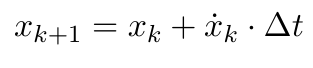

We used dt = 1 (delta t), for simplicity. You can do the same here. However, this time we also have the acceleration and therefore we use:

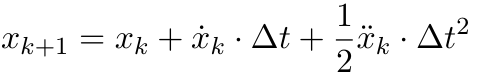

Finally, for a part of the video, the ball is behind something and can't be seen. Obviously we cant update our state here, because there is no measurement. So when there is no measurements available, you should only use the predict function and not the update function, to estimate the state.


# Challenge

If you can't get enough of tracking and Kalman filters, try extending your program, such that it can keep track of multiple balls at the same time. Use the video "rolling_ball_challenge.mp4" to test it. You can take advantage of the balls having different colours.

# Thoughts and comment on challenge

First of all, there are several colored balls in the challenge video, red, blue and yellow. Therefore we have to update our ball detection to be able to detect all the different colors. This could perhaps be done with Hough.circles, but to build on our existing color detection we instead implement the color ranges ot make the correct bound and detect each color of ball present in the challenge video: red, yellow and blue.

Furthermore, we need to keep different states for each ball so they dont overwrite eachother. We simply create a state for each color ball and update them seperately.

Another problem is that when the same color ball is coming from different angles at different times, the state estimation becomes unstable. For example: if the yellow ball disappears to the right, the state estimation will estimate it to be far out of the image coordinates. When it is then introduced again with opposite velocity, the state becomes unstable.

We take a bit of an easy shortcut to deal with this problem by just resetting the states if the ball has not been detected for more than 15 frames. The draw back is that if the ball is hidden for a very long time, this state estimation would loose it.
We also cut of the right most slid of the frames to avoid a problem where the floor color was being detected as a ball. 

In [19]:
# We start by making the ranges or the bounds for the colors of the balls in hsv
# These were found through trial and error and using tools to see the exact color values form the video.
RANGES = {
    "red":    [((0, 130, 60),   (10, 255, 255)),
               ((170, 130, 60), (180, 255, 255))],
    "yellow": [((20, 120, 120), (35, 255, 255))],
    "blue":   [((80, 35, 25),   (105, 255, 255))],
}

# Just a dictionary to color the text and circles correctly.
bgr_colors = {
    "red": (0, 0, 255),
    "yellow": (0, 255, 255),
    "blue": (255, 0, 0)
}

The pictures below were used to estimate the color ranges:

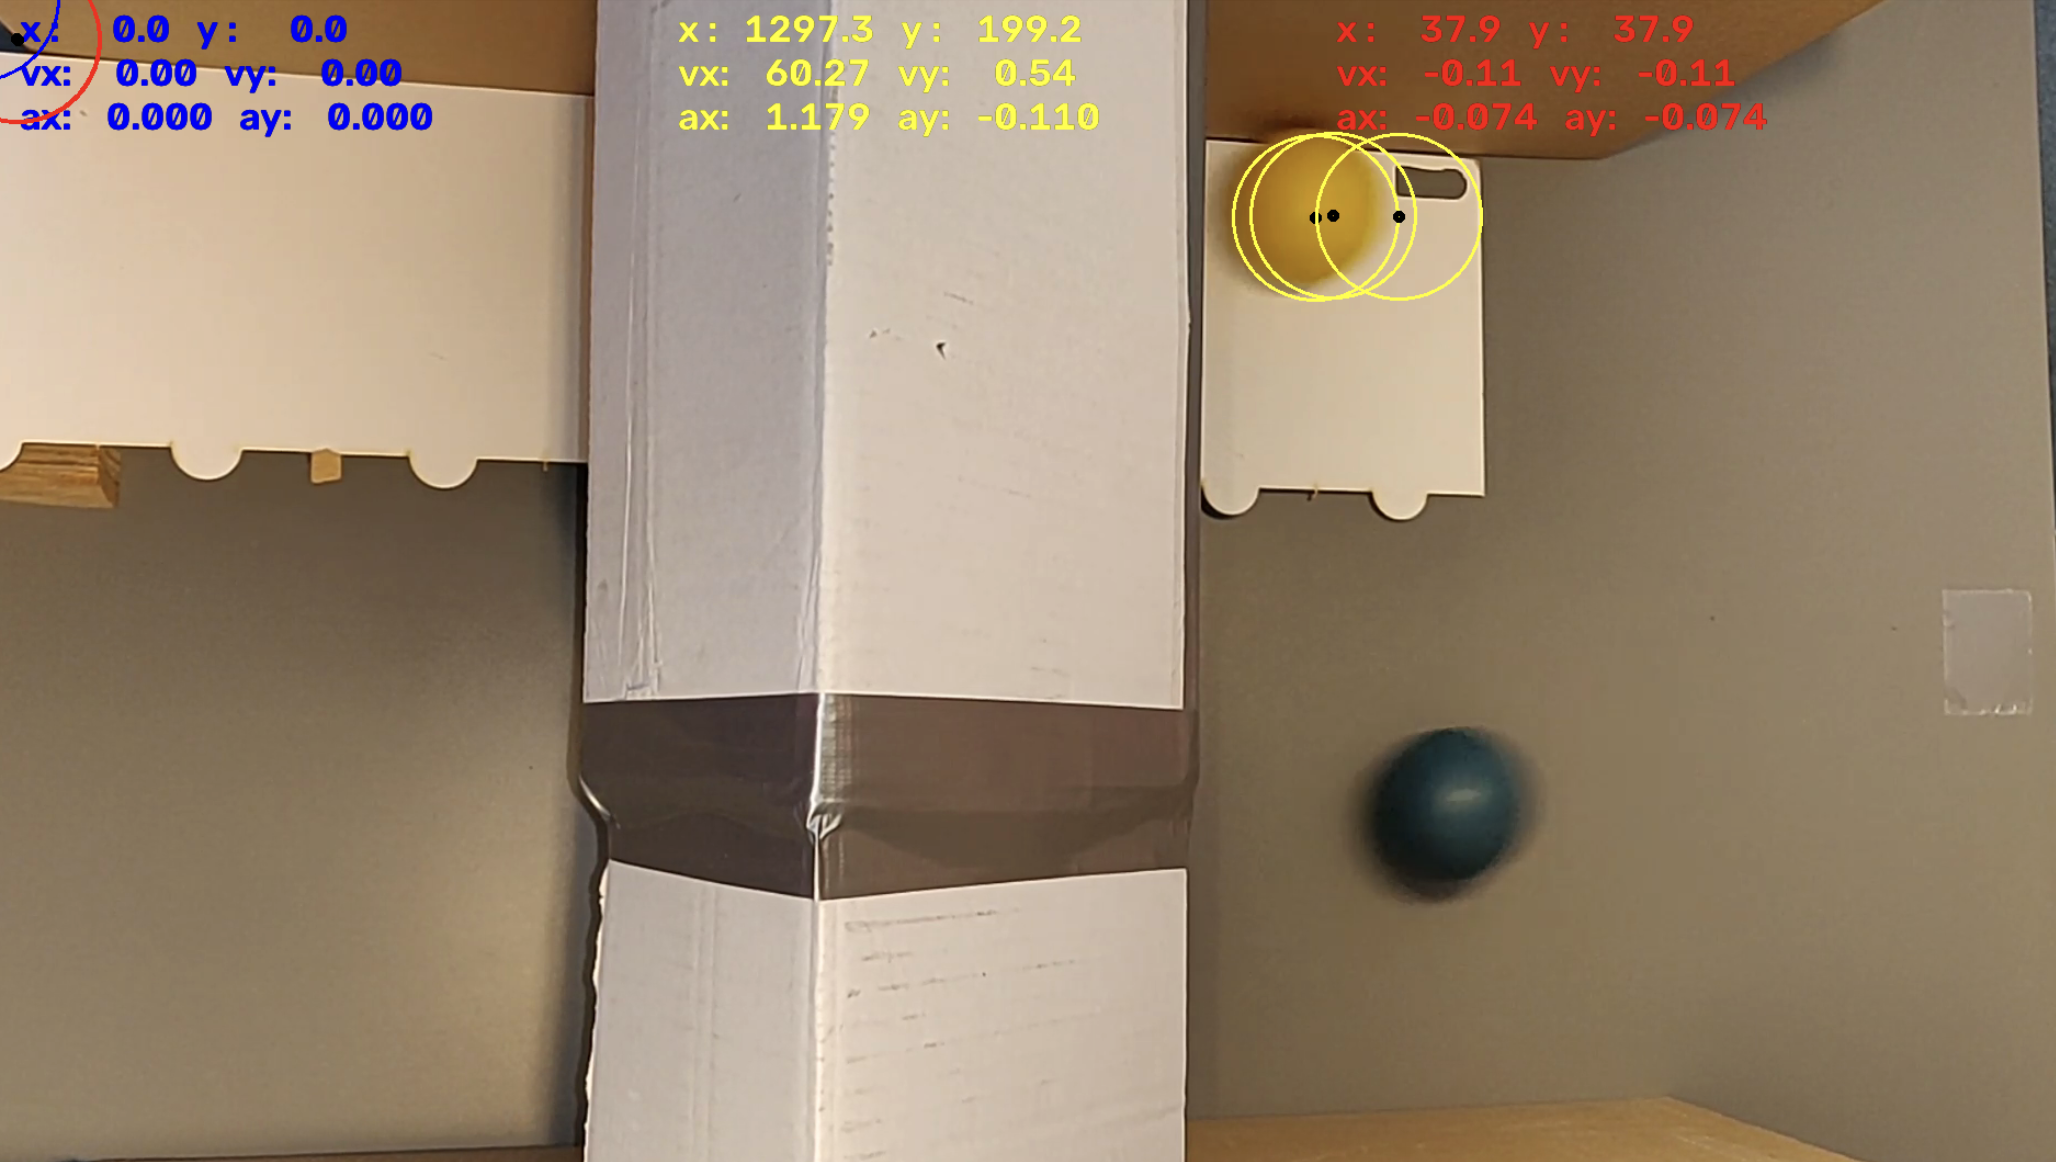
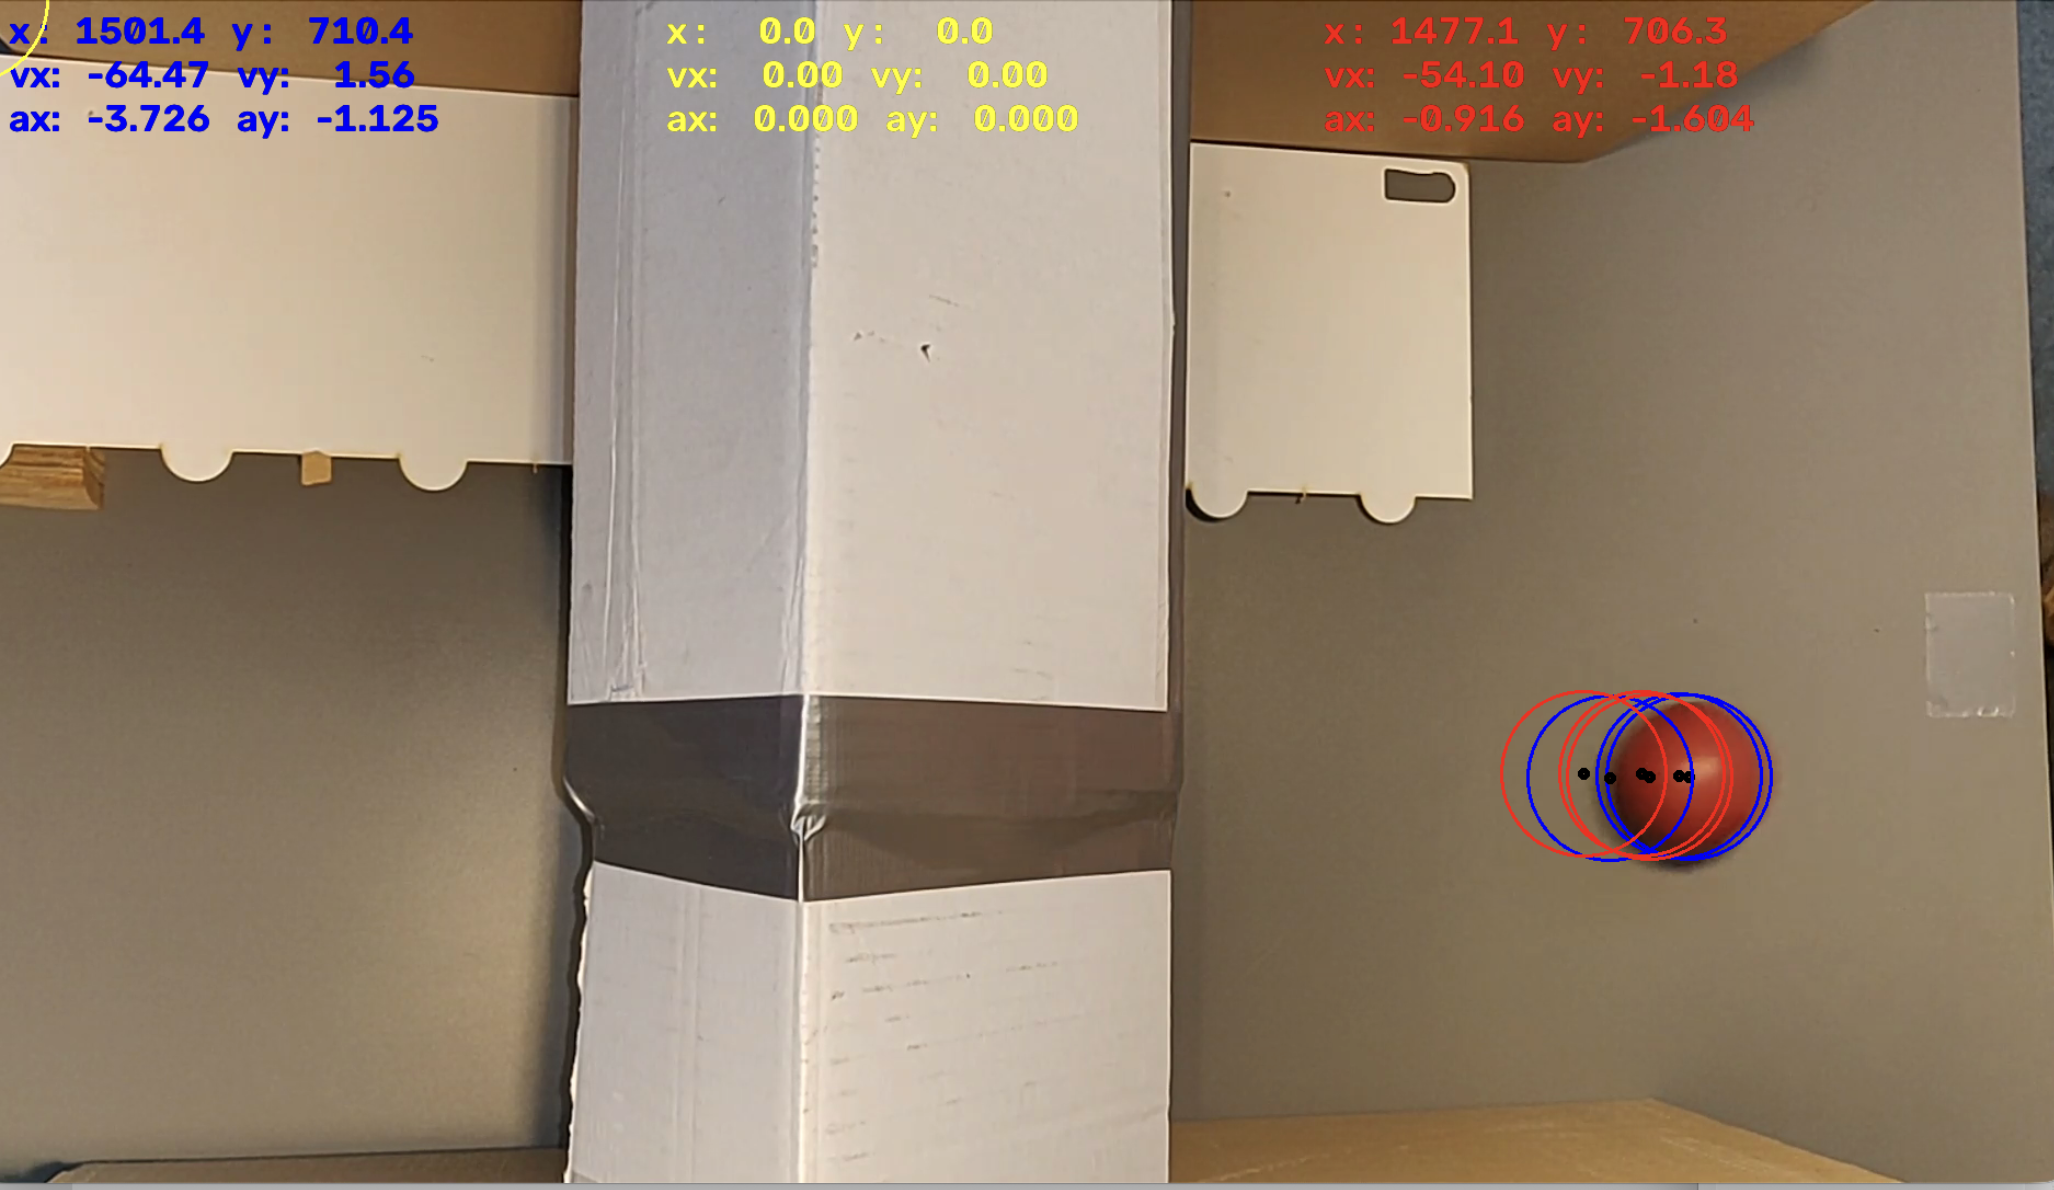

## Redefining some functions
Now we will redefine our functions so the detect_ball function takes the color ranges as input.

The draw_ball and draw_state can draw the circles in specific colors and shades.

In [20]:
# now our function should take these ranges as input.

def detect_ball(frame, color_ranges, min_radius=50):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # Build one mask from all ranges for this color
    mask = np.zeros(hsv.shape[:2], np.uint8)
    for lower, upper in color_ranges:
        mask |= cv2.inRange(hsv, np.array(lower), np.array(upper))

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # Assume the largest contour is the ball
        c = max(contours, key=cv2.contourArea)
        ((cx, cy), radius) = cv2.minEnclosingCircle(c)
        if radius > min_radius:  # Threshold to ignore noise
            return True, int(cx), int(cy)
    return False, None, None

# Use:
# red_found,    red_cx,    red_cy    = detect_ball(frame, RANGES["red"])
# yellow_found, yellow_cx, yellow_cy = detect_ball(frame, RANGES["yellow"])
# blue_found,   blue_cx,   blue_cy   = detect_ball(frame, RANGES["blue"])



def draw_ball(frame, cx, cy, radius, rgb, shade):
    
    color = tuple(c * shade for c in rgb) 
    cv2.circle(frame, (cx, cy), radius, color, 2) # circle
    cv2.circle(frame, (cx, cy), 3, (0, 0, 0), 4) # center


def draw_state(frame, x_state, rgb_color, y_offset):
    ### Draw the state values on the frame ###
    labels = [
        f"x : {x_state[0, 0]:8.1f}   y : {x_state[1, 0]:8.1f}",
        f"vx: {x_state[2, 0]:8.2f}   vy: {x_state[3, 0]:8.2f}",
        f"ax: {x_state[4, 0]:8.3f}   ay: {x_state[5, 0]:8.3f}",
    ]

    for i, text in enumerate(labels):
        pos = (40 + y_offset , 40 + i * 40)  # 30 px line spacing
        # dark outline first so the text stays readable on any background
        cv2.putText(frame, text, pos, cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 6, cv2.LINE_AA)       # outline
        cv2.putText(frame, text, pos, cv2.FONT_HERSHEY_SIMPLEX, 1.2, rgb_color, 2, cv2.LINE_AA) # fill


# Challenge loop

In [21]:
# Load the video
cap = cv2.VideoCapture('rolling_ball_challenge.mp4')
if not cap.isOpened():
    print("Cannot open video")
    exit()


#Video exportation
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 30
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
CROP = 50
out = cv2.VideoWriter('challenge_result.mp4', fourcc, fps,
                      (frame_width - CROP, frame_height))


# One state and covariance per color
states = {color: np.zeros((6, 1)) for color in RANGES}
covs   = {color: np.eye(6) * 1000 for color in RANGES}
frames_without_color = {color: 0 for color in RANGES}
seen   = set()

# Looping through all the frames
while True:
    ret, frame = cap.read()
    if not ret:
        break
    
    # To make a bit easier for ourselves we also crop out the fingers and floor on the right
    frame = frame[:, :-50]   # drop the rightmost 50 columns

    # Do the kalman estimation for each color ball seperately:
    for i, color in enumerate(RANGES):
        if frames_without_color[color] < 15:
            x = states[color]
            P = covs[color]
        else:
            states[color] = np.zeros((6, 1))
            covs[color] = np.eye(6) * 1000
            x = states[color]
            P = covs[color]
            if color in seen:
                seen.remove(color)
            
            

        ball_found, cx, cy = detect_ball(frame, RANGES[color])

        ### If the ball is found, update the Kalman filter ###
        if ball_found:
            draw_ball(frame, cx, cy, 75, bgr_colors[color], shade=0.3)
            z = np.array([[cx], [cy]])
            [x, P] = update(x, P, z, H, R)
            frames_without_color[color] = 0
            seen.add(color)
        else:
            frames_without_color[color] += 1
            

        if color not in seen:
            continue                      # nothing detected yet: draw nothing

        ### Draw the current tracked state ###
        current_cx = int(x[0, 0])
        current_cy = int(x[1, 0])
        draw_ball(frame, current_cx, current_cy, 75, bgr_colors[color], shade=0.7)

        ### Predict the next state ###
        [x, P] = predict(x, P, F, u)

        ### Draw the predicted state ###
        predicted_cx = int(x[0, 0])
        predicted_cy = int(x[1, 0])
        draw_ball(frame, predicted_cx, predicted_cy, 75, bgr_colors[color], shade=1)

        ### Draw state of the ball in text, one block per color ###
        draw_state(frame, x, bgr_colors[color], y_offset=i*600)

        # Save the updated state back
        states[color] = x
        covs[color] = P

    cv2.imshow('Frame', frame)
    out.write(frame)
    cv2.waitKey(50)

cap.release()
out.release()
cv2.destroyAllWindows()